# M5 Hands-on Practical: Regression Metrics, Probability Calibration & Hyperparameter Search

## Dataset
**Small Placement Predict 1K Dataset**

This practical teaches three connected ideas using the supplied placement dataset:

1. **Regression evaluation:** MAE, RMSE, MAPE and R², including the RMSE-vs-MAE decision under outliers.
2. **Probability calibration:** Platt scaling, isotonic regression and reliability diagrams.
3. **Hyperparameter search:** Grid Search, Random Search, and a preview-level Bayesian optimization workflow using a Gaussian Process.

### Learning outcomes

By the end of this notebook, students should be able to:

- calculate and interpret common regression metrics;
- explain why RMSE is more sensitive to large errors than MAE;
- explain what a calibrated probability such as 0.70 means;
- calibrate a classifier using sigmoid/Platt and isotonic methods;
- interpret a reliability diagram;
- distinguish parameters from hyperparameters;
- compare Grid Search and Random Search;
- understand the exploration/exploitation idea behind Gaussian-process Bayesian optimization.

> **Important dataset decision:** `Salary Package` is 0 for unplaced students. Therefore, the salary regression experiment is restricted to students with `PlacementStatus = 1`. This makes MAPE meaningful because the actual salary is positive for the evaluated cases.


In [6]:
# 1. Imports and reproducibility

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold,
    GridSearchCV, RandomizedSearchCV, cross_val_score
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    mean_absolute_percentage_error,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss
)
from sklearn.calibration import (
    CalibratedClassifierCV, CalibrationDisplay,
    calibration_curve
)

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from scipy.stats import randint

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Load and Inspect the Dataset

We first inspect dimensions, variables, missing values, target distributions, and the relationship between placement status and salary.


In [7]:
# 2. Load the supplied dataset

DATA_PATH = "../data/Small_placement_predict_1k_Dataset - Copy(1).csv"
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).head(10))

print("\nPlacement status:")
display(df["PlacementStatus"].value_counts().sort_index())

print("\nSalary summary:")
display(df["Salary Package"].describe())


Shape: (1000, 15)


,StudentID,CGPA,Internships,Projects,AptitudeScore,CommunicationScore,TechnicalScore,Attendance,Gender,Branch,Education,PlacementStatus,Salary Package,CGPA_Tier,IsAnomaly
0,1,7.11,2,1,59,76,55,95.2,Male,EEE,B.Tech,0,0.0,Medium,0
1,2,9.59,3,3,99,67,47,82.3,Female,CIVIL,B.Tech,0,0.0,Excellent,0
2,3,8.65,1,4,72,67,79,69.3,Male,MECH,B.Tech,0,0.0,Excellent,0
3,4,8.07,3,4,65,81,98,80.1,Female,MECH,B.E.,0,0.0,Good,0
4,5,6.17,3,1,78,82,96,89.3,Male,CSE,B.E.,0,0.0,Low,0



Column names:
['StudentID', 'CGPA', 'Internships', 'Projects', 'AptitudeScore', 'CommunicationScore', 'TechnicalScore', 'Attendance', 'Gender', 'Branch', 'Education', 'PlacementStatus', 'Salary Package', 'CGPA_Tier', 'IsAnomaly']

Missing values:


StudentID             0
CGPA                  0
Internships           0
Projects              0
AptitudeScore         0
CommunicationScore    0
TechnicalScore        0
Attendance            0
Gender                0
Branch                0
dtype: int64


Placement status:


PlacementStatus
0    986
1     14
Name: count, dtype: int64


Salary summary:


count    1000.000000
mean        0.139110
std         1.176581
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        11.790000
Name: Salary Package, dtype: float64

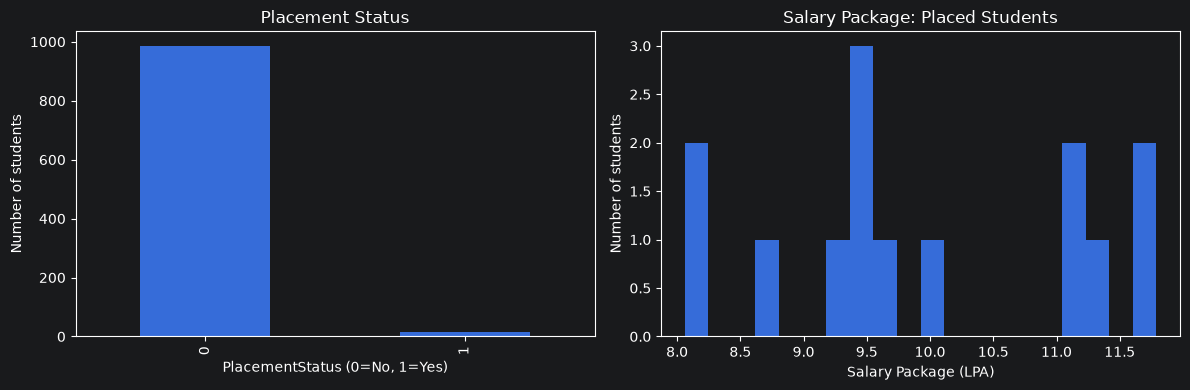

In [8]:
# 3. Quick visual inspection

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["PlacementStatus"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], title="Placement Status"
)
axes[0].set_xlabel("PlacementStatus (0=No, 1=Yes)")
axes[0].set_ylabel("Number of students")

axes[1].hist(df.loc[df["PlacementStatus"] == 1, "Salary Package"], bins=20)
axes[1].set_title("Salary Package: Placed Students")
axes[1].set_xlabel("Salary Package (LPA)")
axes[1].set_ylabel("Number of students")

plt.tight_layout()
plt.show()


# Part A — Regression Metrics

## 3. Salary Prediction

We predict `Salary Package` for **placed students only**.

### Metrics

- **MAE:** average absolute error.
- **RMSE:** square-root of mean squared error; strongly penalizes large errors.
- **MAPE:** average absolute percentage error; problematic when actual values are zero or near zero.
- **R²:** proportion of target variance explained relative to a mean-prediction baseline.

We will compare MAE and RMSE particularly because the dataset contains a range of salary values and potentially influential high-salary observations.


In [9]:
# 4. Prepare the salary-regression dataset

placed = df[df["PlacementStatus"] == 1].copy()

# Remove identifiers, classification-only/leakage columns, and the target.
# CGPA_Tier is derived from CGPA, so it is also excluded here.
drop_reg = [
    "StudentID", "PlacementStatus", "Salary Package",
    "CGPA_Tier", "IsAnomaly"
]

X_reg = placed.drop(columns=drop_reg)
y_reg = placed["Salary Package"]

categorical_reg = X_reg.select_dtypes(include="object").columns.tolist()
numeric_reg = X_reg.select_dtypes(exclude="object").columns.tolist()

reg_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ]), numeric_reg),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_reg)
])

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
)

reg_model = Pipeline([
    ("preprocess", reg_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

reg_model.fit(X_train_reg, y_train_reg)
y_pred_reg = reg_model.predict(X_test_reg)

mae = mean_absolute_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))
mape = mean_absolute_percentage_error(y_test_reg, y_pred_reg) * 100
r2 = r2_score(y_test_reg, y_pred_reg)

print(f"MAE  : {mae:.3f} LPA")
print(f"RMSE : {rmse:.3f} LPA")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.3f}")


MAE  : 1.333 LPA
RMSE : 1.479 LPA
MAPE : 13.20%
R²   : -0.490


## 4. Interpret MAE vs RMSE

The two metrics answer slightly different questions.

### MAE
> "On average, how many LPA away are our predictions?"

### RMSE
> "How large are our errors when large mistakes should receive extra penalty?"

If RMSE is much larger than MAE, investigate whether a small number of large residuals are responsible.

**Teaching rule:**

- Use **MAE** when robustness to outliers is important.
- Use **RMSE** when large prediction errors are especially costly.
- Report both when the consequences of errors are not obvious.


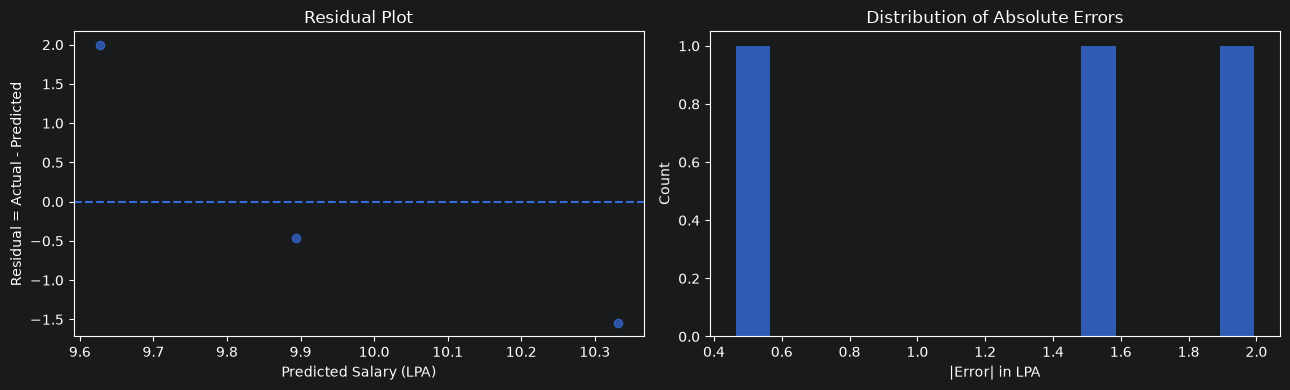

Largest absolute errors:


,Actual,Predicted,AbsoluteError
0,11.62,9.626767,1.993233
2,8.79,10.331333,1.541333
1,9.43,9.894400,0.464400


In [10]:
# 5. Visualize residuals and compare absolute vs squared error

residuals = y_test_reg - y_pred_reg

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].scatter(y_pred_reg, residuals, alpha=0.7)
axes[0].axhline(0, linestyle="--")
axes[0].set_xlabel("Predicted Salary (LPA)")
axes[0].set_ylabel("Residual = Actual - Predicted")
axes[0].set_title("Residual Plot")

axes[1].hist(np.abs(residuals), bins=15, alpha=0.8, label="Absolute error")
axes[1].set_xlabel("|Error| in LPA")
axes[1].set_ylabel("Count")
axes[1].set_title("Distribution of Absolute Errors")

plt.tight_layout()
plt.show()

print("Largest absolute errors:")
display(
    pd.DataFrame({
        "Actual": y_test_reg.values,
        "Predicted": y_pred_reg,
        "AbsoluteError": np.abs(residuals.values)
    }).sort_values("AbsoluteError", ascending=False).head(10)
)


# Part B — Probability Calibration

Now we change the task.

Instead of predicting salary, we predict:

**Will the student be placed?**

Target:

`PlacementStatus`

A classifier might output:

```text
Student A → 0.70
```

A calibrated 0.70 means that, among many students assigned probabilities around 0.70, approximately 70% should actually be placed.

Calibration is different from accuracy: a model can rank students well but still produce probabilities that are too high or too low.


In [11]:
# 6. Prepare the placement-classification dataset

drop_cls = [
    "StudentID",
    "PlacementStatus",
    "Salary Package",
    "IsAnomaly",
    "CGPA_Tier"
]

X_cls = df.drop(columns=drop_cls)
y_cls = df["PlacementStatus"]

categorical_cls = X_cls.select_dtypes(include="object").columns.tolist()
numeric_cls = X_cls.select_dtypes(exclude="object").columns.tolist()

cls_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cls),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cls)
])

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls,
    test_size=0.20,
    stratify=y_cls,
    random_state=RANDOM_STATE
)

base_clf = Pipeline([
    ("preprocess", cls_preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

base_clf.fit(X_train_cls, y_train_cls)

p_base = base_clf.predict_proba(X_test_cls)[:, 1]
y_base = (p_base >= 0.5).astype(int)

print("Accuracy :", accuracy_score(y_test_cls, y_base))
print("Precision:", precision_score(y_test_cls, y_base))
print("Recall   :", recall_score(y_test_cls, y_base))
print("F1       :", f1_score(y_test_cls, y_base))
print("ROC-AUC  :", roc_auc_score(y_test_cls, p_base))
print("Brier    :", brier_score_loss(y_test_cls, p_base))


Accuracy : 0.985
Precision: 0.0
Recall   : 0.0
F1       : 0.0
ROC-AUC  : 0.8663282571912013
Brier    : 0.014275159427707984


## 7. Platt Scaling and Isotonic Regression

`CalibratedClassifierCV` provides two important calibration approaches:

- `method="sigmoid"` → **Platt-style sigmoid calibration**
- `method="isotonic"` → **isotonic regression calibration**

For teaching purposes we use cross-validation inside the calibration procedure so that calibration is not simply learned from the same observations used to fit the base classifier.

> With only about 1,000 observations, isotonic regression should be interpreted cautiously because its flexibility can make it more data-hungry than sigmoid calibration.


In [12]:
# 7. Calibrate the classifier

sigmoid_calibrated = CalibratedClassifierCV(
    estimator=base_clf,
    method="sigmoid",
    cv=5
)

isotonic_calibrated = CalibratedClassifierCV(
    estimator=base_clf,
    method="isotonic",
    cv=5
)

sigmoid_calibrated.fit(X_train_cls, y_train_cls)
isotonic_calibrated.fit(X_train_cls, y_train_cls)

p_sigmoid = sigmoid_calibrated.predict_proba(X_test_cls)[:, 1]
p_isotonic = isotonic_calibrated.predict_proba(X_test_cls)[:, 1]

calibration_results = pd.DataFrame({
    "Model": ["Uncalibrated", "Platt/Sigmoid", "Isotonic"],
    "ROC-AUC": [
        roc_auc_score(y_test_cls, p_base),
        roc_auc_score(y_test_cls, p_sigmoid),
        roc_auc_score(y_test_cls, p_isotonic)
    ],
    "Brier Score": [
        brier_score_loss(y_test_cls, p_base),
        brier_score_loss(y_test_cls, p_sigmoid),
        brier_score_loss(y_test_cls, p_isotonic)
    ]
})

display(calibration_results)


,Model,ROC-AUC,Brier Score
0,Uncalibrated,0.866328,0.014275
1,Platt/Sigmoid,0.837563,0.014602
2,Isotonic,0.808799,0.014498


## 8. Reliability Diagram

A reliability diagram compares:

- **x-axis:** mean predicted probability
- **y-axis:** observed fraction of positives

A perfectly calibrated model lies close to the diagonal:

\[
y=x
\]

Below the diagonal generally indicates overconfidence; above it generally indicates underconfidence.


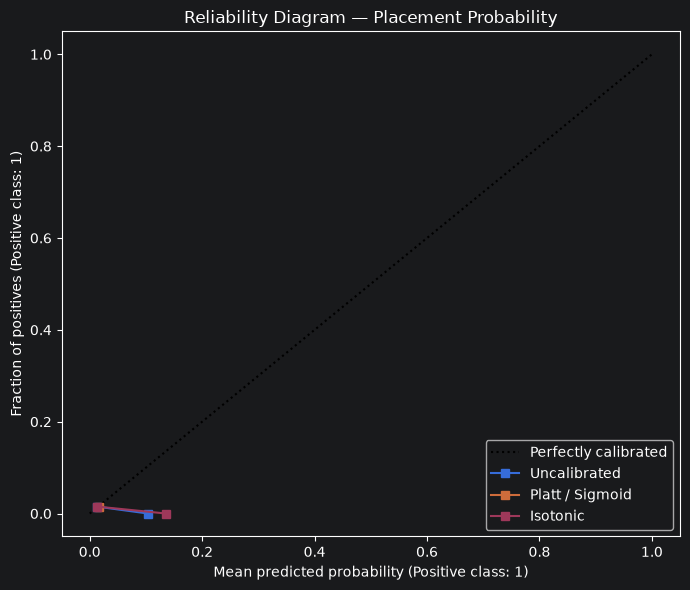

In [13]:
# 8. Reliability diagrams

fig, ax = plt.subplots(figsize=(7, 6))

CalibrationDisplay.from_predictions(
    y_test_cls, p_base,
    n_bins=10,
    strategy="uniform",
    name="Uncalibrated",
    ax=ax
)

CalibrationDisplay.from_predictions(
    y_test_cls, p_sigmoid,
    n_bins=10,
    strategy="uniform",
    name="Platt / Sigmoid",
    ax=ax
)

CalibrationDisplay.from_predictions(
    y_test_cls, p_isotonic,
    n_bins=10,
    strategy="uniform",
    name="Isotonic",
    ax=ax
)

ax.set_title("Reliability Diagram — Placement Probability")
plt.tight_layout()
plt.show()


In [14]:
# 9. Inspect calibration bins numerically

def calibration_table(y_true, prob, n_bins=10):
    frac_pos, mean_pred = calibration_curve(
        y_true, prob, n_bins=n_bins, strategy="uniform"
    )
    return pd.DataFrame({
        "Mean predicted probability": mean_pred,
        "Observed positive fraction": frac_pos,
        "Difference (observed - predicted)": frac_pos - mean_pred
    })

print("Platt / Sigmoid calibration:")
display(calibration_table(y_test_cls, p_sigmoid))

print("Isotonic calibration:")
display(calibration_table(y_test_cls, p_isotonic))


Platt / Sigmoid calibration:


,Mean predicted probability,Observed positive fraction,Difference (observed - predicted)
0,0.016619,0.015,-0.001619


Isotonic calibration:


,Mean predicted probability,Observed positive fraction,Difference (observed - predicted)
0,0.012583,0.015228,0.002645
1,0.135784,0.000000,-0.135784


## 9. Classroom Exercise: Is 0.70 Really 70%?

Use the following procedure:

1. Select test observations whose predicted probabilities are approximately 0.65–0.75.
2. Calculate their observed placement rate.
3. Compare that rate with 0.70.
4. Repeat for other probability ranges.

### Interpretation

If 100 students receive probabilities around 0.70 and approximately 70 are actually placed, the probabilities are behaving as expected.

If only 50 are placed, the model is overconfident around 0.70.


In [15]:
# 10. Empirical check around probability 0.70

def probability_band_report(y_true, prob, low=0.65, high=0.75):
    mask = (prob >= low) & (prob < high)
    subset = pd.DataFrame({
        "Actual": np.asarray(y_true)[mask],
        "PredictedProbability": np.asarray(prob)[mask]
    })
    print(f"Number of students in [{low}, {high}):", len(subset))
    if len(subset):
        print("Mean predicted probability:", subset["PredictedProbability"].mean())
        print("Observed placement rate :", subset["Actual"].mean())
    return subset

band = probability_band_report(y_test_cls, p_sigmoid, 0.65, 0.75)
display(band.head(20))


Number of students in [0.65, 0.75): 0


,Actual,PredictedProbability


# Part C — Hyperparameter Search

We now tune a Random Forest classifier.

### Hyperparameters

- `n_estimators`: number of trees
- `max_depth`: maximum depth of each tree
- `min_samples_split`: minimum samples required to split an internal node

We will compare:

1. **Grid Search** — systematically tests all specified combinations.
2. **Random Search** — samples combinations randomly.
3. **Bayesian optimization preview** — uses a Gaussian Process surrogate to reason about promising regions.

All search decisions must use **cross-validation on the training data**. The final test set remains isolated until the end.


In [16]:
# 11. Random Forest pipeline for hyperparameter search

rf_pipeline = Pipeline([
    ("preprocess", cls_preprocessor),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [5, 10, 15, None],
    "model__min_samples_split": [2, 5]
}

print("Total Grid Search combinations:",
      np.prod([len(v) for v in param_grid.values()]))


Total Grid Search combinations: 24


In [17]:
# 12. Grid Search

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train_cls, y_train_cls)

print("Best Grid Search ROC-AUC:", grid_search.best_score_)
print("Best parameters:")
print(grid_search.best_params_)


Best Grid Search ROC-AUC: 0.5092087935714478
Best parameters:
{'model__max_depth': 15, 'model__min_samples_split': 2, 'model__n_estimators': 200}


In [18]:
# 13. Random Search

random_distributions = {
    "model__n_estimators": randint(80, 401),
    "model__max_depth": [5, 8, 10, 12, 15, 20, None],
    "model__min_samples_split": randint(2, 11)
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=random_distributions,
    n_iter=20,
    scoring="roc_auc",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True
)

random_search.fit(X_train_cls, y_train_cls)

print("Best Random Search ROC-AUC:", random_search.best_score_)
print("Best parameters:")
print(random_search.best_params_)


Best Random Search ROC-AUC: 0.5548946491440242
Best parameters:
{'model__max_depth': 12, 'model__min_samples_split': 3, 'model__n_estimators': 344}


## 10. Why Random Search Can Be Efficient

Suppose only `max_depth` strongly influences validation performance while the other hyperparameters have weaker effects.

Grid search spends experiments on a regular lattice.

Random search distributes trials across the search space, so with the same computational budget it may sample more distinct values of an important hyperparameter.

This is the central intuition behind the **Bergstra–Bengio random-search argument**.

It is not a guarantee that random search always wins; the result depends on the search space, budget and objective.


# Part D — Bayesian Optimization Preview with a Gaussian Process

This section is deliberately a **preview**, not a full production Bayesian-optimization package.

We use a Gaussian Process to model:

\[
	ext{hyperparameter values} ightarrow 	ext{cross-validation ROC-AUC}
\]

Then we use an acquisition idea based on **Expected Improvement (EI)** to choose a promising next configuration.

The important learning objective is the loop:

```text
Evaluate configurations
        ↓
Fit Gaussian Process
        ↓
Predict mean + uncertainty
        ↓
Compute acquisition value
        ↓
Choose next configuration
        ↓
Evaluate it
        ↓
Update the Gaussian Process
```


In [19]:
# 14. Bayesian optimization preview
# We optimize two hyperparameters while keeping min_samples_split fixed.

from sklearn.base import clone

def evaluate_rf_config(n_estimators, max_depth, min_samples_split=2):
    model = clone(rf_pipeline)
    model.set_params(
        model__n_estimators=int(n_estimators),
        model__max_depth=None if max_depth >= 19.5 else int(round(max_depth)),
        model__min_samples_split=int(min_samples_split)
    )
    scores = cross_val_score(
        model,
        X_train_cls,
        y_train_cls,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )
    return scores.mean()

# Candidate space
candidate_n = np.arange(80, 401, 20)
candidate_depth = np.arange(4, 21, 1)

candidates = np.array([
    [n, d] for n in candidate_n for d in candidate_depth
], dtype=float)

# Initial design: spread points across the space
initial_idx = np.linspace(0, len(candidates)-1, 8, dtype=int)
X_obs = candidates[initial_idx]

y_obs = np.array([
    evaluate_rf_config(n, d)
    for n, d in X_obs
])

print("Initial observations:", len(y_obs))
display(pd.DataFrame(X_obs, columns=["n_estimators", "max_depth"]).assign(ROC_AUC=y_obs))


Initial observations: 8


,n_estimators,max_depth,ROC_AUC
0,80.0,4.0,0.438362
1,120.0,11.0,0.455352
2,160.0,18.0,0.482338
3,220.0,8.0,0.517777
4,260.0,15.0,0.480796
5,320.0,5.0,0.457405
6,360.0,12.0,0.471394
7,400.0,20.0,0.478873


In [20]:
# 15. Expected Improvement (EI) helper

def expected_improvement(X_candidates, gp, y_best, xi=0.01):
    mu, sigma = gp.predict(X_candidates, return_std=True)
    sigma = np.maximum(sigma, 1e-9)

    from scipy.stats import norm

    improvement = mu - y_best - xi
    Z = improvement / sigma
    ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
    return ei

# Run a small number of Bayesian optimization iterations.
# This is intentionally modest because each candidate requires 5-fold CV.

history = []

for iteration in range(5):
    kernel = (
        ConstantKernel(1.0, (1e-3, 1e3))
        * Matern(length_scale=[100, 5], nu=2.5)
        + WhiteKernel(noise_level=1e-4)
    )

    gp = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        random_state=RANDOM_STATE
    )

    gp.fit(X_obs, y_obs)

    mask = np.ones(len(candidates), dtype=bool)
    for x in X_obs:
        mask &= ~np.all(np.isclose(candidates, x), axis=1)

    X_remaining = candidates[mask]

    if len(X_remaining) == 0:
        break

    ei = expected_improvement(
        X_remaining, gp, y_best=np.max(y_obs), xi=0.01
    )

    next_x = X_remaining[np.argmax(ei)]
    next_score = evaluate_rf_config(next_x[0], next_x[1])

    X_obs = np.vstack([X_obs, next_x])
    y_obs = np.append(y_obs, next_score)

    history.append({
        "Iteration": iteration + 1,
        "n_estimators": next_x[0],
        "max_depth": next_x[1],
        "ROC_AUC": next_score
    })

display(pd.DataFrame(history))

best_idx = np.argmax(y_obs)
print("Best Bayesian-preview configuration:")
print("n_estimators =", int(X_obs[best_idx, 0]))
print("max_depth    =", int(X_obs[best_idx, 1]))
print("CV ROC-AUC    =", round(y_obs[best_idx], 4))


,Iteration,n_estimators,max_depth,ROC_AUC
0,1,200.0,20.0,0.509209
1,2,200.0,4.0,0.460354
2,3,320.0,8.0,0.495228
3,4,140.0,8.0,0.506629
4,5,80.0,20.0,0.487170


Best Bayesian-preview configuration:
n_estimators = 220
max_depth    = 8
CV ROC-AUC    = 0.5178


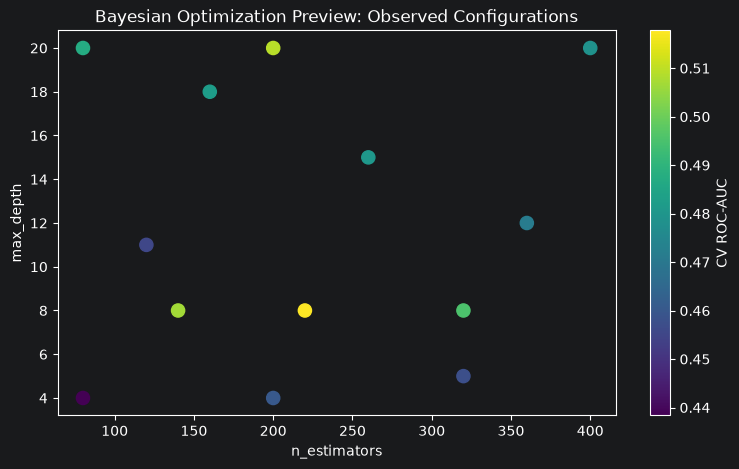

In [21]:
# 16. Visualize the Bayesian optimization observations

plt.figure(figsize=(9, 5))
sc = plt.scatter(
    X_obs[:, 0],
    X_obs[:, 1],
    c=y_obs,
    s=90
)
plt.colorbar(sc, label="CV ROC-AUC")
plt.xlabel("n_estimators")
plt.ylabel("max_depth")
plt.title("Bayesian Optimization Preview: Observed Configurations")
plt.show()


## 11. Compare Search Methods

The CV scores below are **training-set cross-validation results** used for selecting hyperparameters.

Do not use these scores as the final generalization estimate. The isolated test set is evaluated only after selection.


In [22]:
# 17. Final test-set comparison

best_grid = grid_search.best_estimator_
best_random = random_search.best_estimator_

# Build the best model from the Bayesian preview
best_bayes_model = clone(rf_pipeline)
best_bayes_model.set_params(
    model__n_estimators=int(X_obs[best_idx, 0]),
    model__max_depth=int(X_obs[best_idx, 1]),
    model__min_samples_split=2
)
best_bayes_model.fit(X_train_cls, y_train_cls)

models = {
    "Grid Search": best_grid,
    "Random Search": best_random,
    "Bayesian Preview": best_bayes_model
}

comparison = []

for name, model in models.items():
    p = model.predict_proba(X_test_cls)[:, 1]
    pred = (p >= 0.5).astype(int)

    comparison.append({
        "Method": name,
        "Test ROC-AUC": roc_auc_score(y_test_cls, p),
        "Test Accuracy": accuracy_score(y_test_cls, pred),
        "Test F1": f1_score(y_test_cls, pred),
        "Brier Score": brier_score_loss(y_test_cls, p)
    })

comparison_df = pd.DataFrame(comparison).sort_values(
    "Test ROC-AUC", ascending=False
)

display(comparison_df)


,Method,Test ROC-AUC,Test Accuracy,Test F1,Brier Score
0,Grid Search,0.873942,0.985,0.0,0.013824
2,Bayesian Preview,0.820643,0.985,0.0,0.014175
1,Random Search,0.761421,0.985,0.0,0.014058


# 12. Final Interpretation

When teaching or reporting this practical, do **not** say that one search method is universally best.

Instead, ask:

### Regression

- Is MAE lower than RMSE?
- Are there unusually large residuals?
- Does the application care strongly about large mistakes?
- Is MAPE appropriate for this target?

### Calibration

- Does the reliability curve follow the diagonal?
- Is the model overconfident or underconfident?
- Does Platt/sigmoid improve Brier score?
- Does isotonic improve calibration without becoming unstable?

### Hyperparameter search

- How many configurations were evaluated?
- How much CV computation was required?
- Did Random Search explore the important dimensions efficiently?
- Did the Bayesian preview use previous observations to choose new trials?
- How did the final selected models perform on the untouched test set?

---

# 13. Important Experimental Discipline

Use this structure in future ML projects:

```text
Full dataset
     │
     ├── Training data
     │      │
     │      └── Cross-validation
     │             ├── Grid Search
     │             ├── Random Search
     │             └── Bayesian Optimization
     │
     └── Test data
            │
            └── ONE final evaluation
```

For calibration, calibration data/model selection must also be handled without contaminating the final test set.

## Main takeaway

**Metrics evaluate predictions.**

**Calibration evaluates whether probabilities mean what they claim.**

**Hyperparameter search finds model configurations efficiently.**

These are different stages of a rigorous machine-learning workflow.


# 14. Student Tasks

### Task 1 — Regression
Change the Random Forest regression hyperparameters and investigate:

- What happens to MAE?
- What happens to RMSE?
- Which observations have the largest errors?
- Does removing extreme salary observations change the RMSE more than the MAE?

### Task 2 — Calibration
Compare:

- uncalibrated probabilities;
- Platt/sigmoid calibration;
- isotonic calibration.

Report:

- Brier score;
- reliability diagram;
- interpretation around probability 0.70.

### Task 3 — Hyperparameter Search
Change the Random Search budget from:

```python
n_iter=20
```

to:

```python
n_iter=5
n_iter=10
n_iter=30
```

Record the best CV ROC-AUC and final test ROC-AUC.

### Task 4 — Critical Thinking
Answer:

1. Why can a model have high ROC-AUC but poor calibration?
2. Why is MAPE unsuitable when actual target values are zero?
3. Why does RMSE react more strongly to outliers than MAE?
4. Why can Random Search outperform Grid Search when only a few hyperparameters matter?
5. What is the exploration/exploitation trade-off in Bayesian optimization?
